<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet%2011/Praktikum%201%20(JS11).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1 - Import Library & Load Dataset

In [2]:
# Import library yang dibutuhkan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Memuat dataset cafes.csv dan reviews.csv
cafes_df = pd.read_csv('cafes.csv')
reviews_df = pd.read_csv('reviews.csv')

print("Jumlah data cafe:", cafes_df.shape)
print("Jumlah data review:", reviews_df.shape)

Jumlah data cafe: (99, 12)
Jumlah data review: (2230, 8)


#Langkah 2 - Preprocessing & Ekstraksi Fitur (Menggabungkan 2 Dataset)

In [3]:
# Agregasi data review per cafe_id dari reviews.csv
reviews_agg = reviews_df.groupby('cafe_id').agg(
    avg_review_rating=('rating', 'mean'),
    total_scraped_reviews=('review_id', 'count')
).reset_index()

# Menggabungkan dengan cafes.csv
merged_df = pd.merge(cafes_df, reviews_agg, on='cafe_id', how='inner')
merged_df = merged_df.dropna(subset=['rating', 'avg_review_rating'])

# Menyiapkan Fitur (X) dan Label (y)
# Fitur X: [rating kafe, rata-rata rating review]
X = merged_df[['rating', 'avg_review_rating']].values

# Label y: 1 jika rating kafe >= 4.7, dan 0 jika < 4.7
y = (merged_df['rating'] >= 4.7).astype(int).values

# Melakukan standardisasi fitur agar skala seimbang
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Distribusi kelas y:", np.bincount(y))

Distribusi kelas y: [37 57]


#Langkah 3 - Visualisasi Sebaran Data (Scatter Plot)

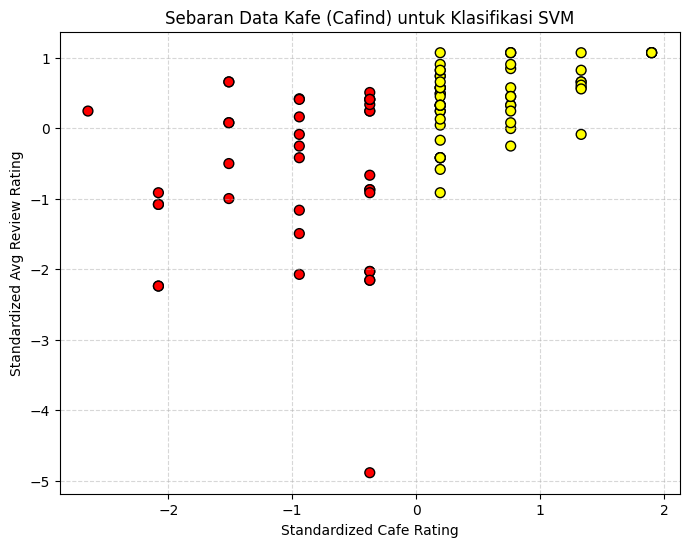

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')
plt.xlabel('Standardized Cafe Rating')
plt.ylabel('Standardized Avg Review Rating')
plt.title('Sebaran Data Kafe (Cafind) untuk Klasifikasi SVM')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#Langkah 4 - Fitting Model SVM (Linear Kernel)

In [14]:
# Inisialisasi dan latih model SVM dengan kernel linier
model = SVC(kernel='linear', C=1E10)
model.fit(X_scaled, y)

print("Model SVM berhasil!")

Model SVM berhasil!


#Langkah 5 - Membuat Fungsi Visualisasi Batas Keputusan & Margin

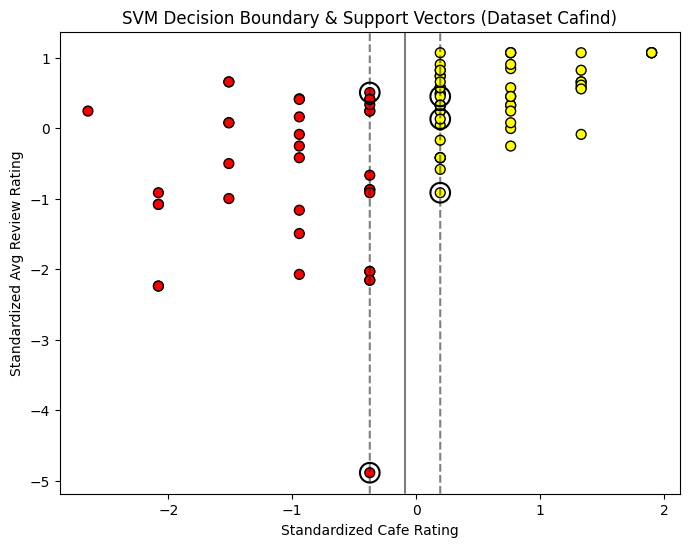

In [6]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # Plot batas dan margin
    ax.contour(X_grid, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=200, linewidth=1.5, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# Melakukan plotting hasil fitting model pada data kafe
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')
plot_svc_decision_function(model)
plt.xlabel('Standardized Cafe Rating')
plt.ylabel('Standardized Avg Review Rating')
plt.title('SVM Decision Boundary & Support Vectors (Dataset Cafind)')
plt.show()

#Langkah 6 - Menampilkan Titik Support Vector

In [7]:
# Menampilkan koordinat support vectors
support_vectors_original = scaler.inverse_transform(model.support_vectors_)
print("Koordinat Support Vectors (Skala Asli - [Rating Kafe, Avg Review Rating]):")
print(support_vectors_original)

Koordinat Support Vectors (Skala Asli - [Rating Kafe, Avg Review Rating]):
[[4.6        2.6       ]
 [4.6        4.77272727]
 [4.7        4.2       ]
 [4.7        4.75      ]
 [4.7        4.62068966]]
